In [1]:
!pip install -q koreanize-matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib

# 2025년 기준 전국 17개 시도
regions = [
    '서울특별시', '부산광역시', '대구광역시',
    '인천광역시', '광주광역시', '대전광역시',
    '울산광역시', '세종특별자치시', '경기도',
    '강원특별자치도', '충청북도', '충청남도',
    '전북특별자치도', '전라남도', '경상북도',
    '경상남도', '제주특별자치도'
]

# 2025년 지역별 면적(㎢)
# 출처: 국토교통부 지적통계연보, 국가지표체계
areas = [
    605.2, 771.7, 1499.7,
    1069.6, 500.9, 539.8,
    1062.9, 465.0, 10207.7,
    16831.2, 7406.7, 8248.1,
    8077.7, 12364.3, 18428.2,
    10543.5, 1850.1
]

# 2025년 12월 말 지역별 주민등록인구(명)
# 출처: 행정안전부 주민등록인구현황
populations = [
    9299548, 3241600, 2353032,
    3051961, 1392013, 1440729,
    1091948, 391965, 13730135,
    1508500, 1596502, 2136753,
    1724856, 1779135, 2506526,
    3207383, 664792
]

# 지역별 면적 데이터프레임 생성
area_df = pd.DataFrame({
    '지역': regions,
    '면적': areas
})

# 지역별 인구 데이터프레임 생성
population_df = pd.DataFrame({
    '지역': regions,
    '총인구수': populations
})

# CSV 파일로 저장
area_df.to_csv(
    '지역별면적.csv',
    index=False,
    encoding='utf-8-sig'
)

population_df.to_csv(
    '지역별인구수.csv',
    index=False,
    encoding='utf-8-sig'
)

print('지역별 면적과 인구수 CSV 파일 생성 완료')

display(area_df)
display(population_df)

지역별 면적과 인구수 CSV 파일 생성 완료


,지역,면적
0,서울특별시,605.2
1,부산광역시,771.7
2,대구광역시,1499.7
3,인천광역시,1069.6
4,광주광역시,500.9
5,대전광역시,539.8
6,울산광역시,1062.9
7,세종특별자치시,465.0
8,경기도,10207.7
9,강원특별자치도,16831.2


,지역,총인구수
0,서울특별시,9299548
1,부산광역시,3241600
2,대구광역시,2353032
3,인천광역시,3051961
4,광주광역시,1392013
5,대전광역시,1440729
6,울산광역시,1091948
7,세종특별자치시,391965
8,경기도,13730135
9,강원특별자치도,1508500


In [3]:
# CSV 파일 불러오기
df1 = pd.read_csv(
    '지역별면적.csv',
    encoding='utf-8-sig'
)

df2 = pd.read_csv(
    '지역별인구수.csv',
    encoding='utf-8-sig'
)

# 지역명을 기준으로 두 데이터 합치기
df = pd.merge(
    df1, df2,
    on='지역',
    validate='one_to_one'
)

# 데이터가 정상적으로 병합되었는지 확인
assert len(df) == 17
assert (df['면적'] > 0).all()
assert df['총인구수'].sum() == 51117378

# 인구밀도 계산
df['인구밀도'] = df['총인구수'] / df['면적']

print('2025년 지역별 인구밀도')
display(df.round(1))

# 인구밀도가 2000명 이상인 지역 확인
print('인구밀도가 2000명/㎢ 이상인 지역')
display(df[df['인구밀도'] >= 2000].round(1))

# 인구밀도가 가장 높은 지역 확인
max_region = df.loc[df['인구밀도'].idxmax()]

print(
    '인구밀도가 가장 높은 지역:',
    max_region['지역']
)

# 인구밀도가 가장 낮은 지역 확인
min_region = df.loc[df['인구밀도'].idxmin()]

print(
    '인구밀도가 가장 낮은 지역:',
    min_region['지역']
)

2025년 지역별 인구밀도


,지역,면적,총인구수,인구밀도
0,서울특별시,605.2,9299548,15366.1
1,부산광역시,771.7,3241600,4200.6
2,대구광역시,1499.7,2353032,1569.0
3,인천광역시,1069.6,3051961,2853.4
4,광주광역시,500.9,1392013,2779.0
5,대전광역시,539.8,1440729,2669.0
6,울산광역시,1062.9,1091948,1027.3
7,세종특별자치시,465.0,391965,842.9
8,경기도,10207.7,13730135,1345.1
9,강원특별자치도,16831.2,1508500,89.6


인구밀도가 2000명/㎢ 이상인 지역


,지역,면적,총인구수,인구밀도
0,서울특별시,605.2,9299548,15366.1
1,부산광역시,771.7,3241600,4200.6
3,인천광역시,1069.6,3051961,2853.4
4,광주광역시,500.9,1392013,2779.0
5,대전광역시,539.8,1440729,2669.0


인구밀도가 가장 높은 지역: 서울특별시
인구밀도가 가장 낮은 지역: 강원특별자치도


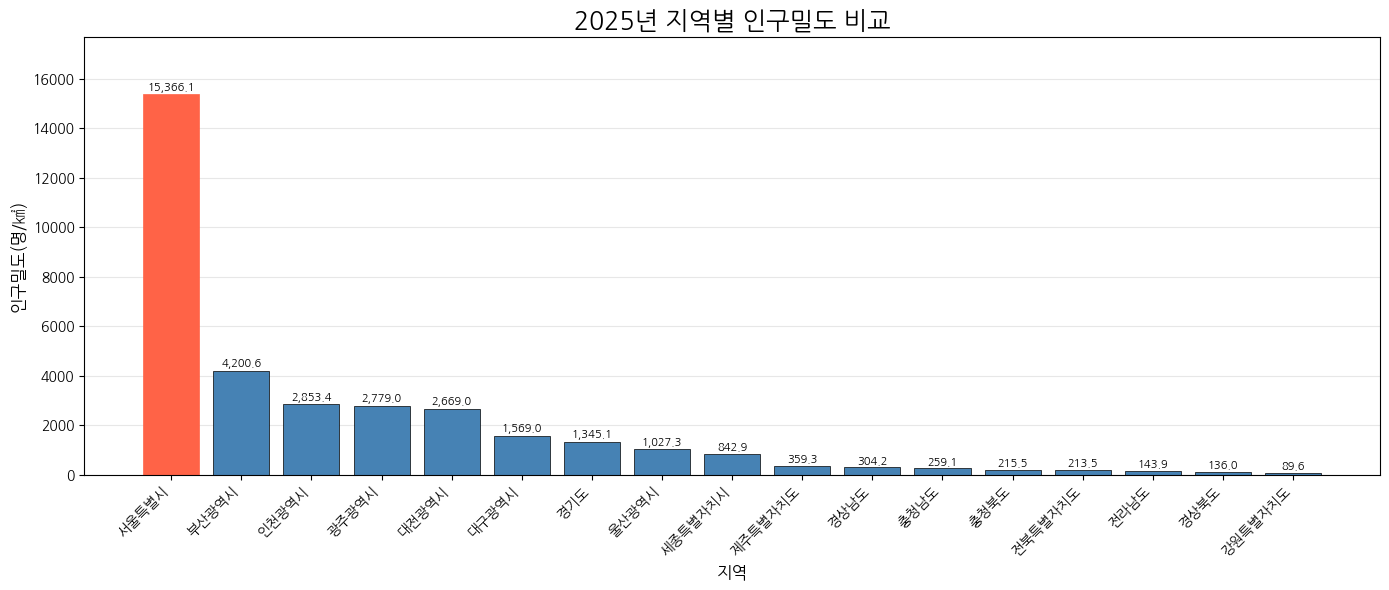

In [4]:
# 인구밀도가 높은 순서대로 정렬
df = df.sort_values(
    by='인구밀도',
    ascending=False
).reset_index(drop=True)

# 그래프의 x축 위치 설정
ind = np.arange(len(df))

# 그래프 크기 설정
plt.figure(figsize=(14, 6))

# 막대그래프 생성
bars = plt.bar(
    ind,
    df['인구밀도'],
    color='steelblue',
    edgecolor='black',
    linewidth=0.5
)

# 인구밀도가 가장 높은 지역 강조
bars[0].set_color('tomato')

# 그래프 제목과 축 이름
plt.title(
    '2025년 지역별 인구밀도 비교',
    fontsize=18
)

plt.xlabel('지역', fontsize=12)
plt.ylabel('인구밀도(명/㎢)', fontsize=12)

# x축에 지역 이름 표시
plt.xticks(
    ind,
    df['지역'],
    rotation=45,
    ha='right'
)

# 막대 위에 인구밀도 표시
for i, value in enumerate(df['인구밀도']):
    plt.text(
        i,
        value + 150,
        f'{value:,.1f}',
        ha='center',
        fontsize=8
    )

# 그래프 출력 설정
plt.ylim(0, df['인구밀도'].max() * 1.15)
plt.grid(axis='y', alpha=0.3)
plt.gca().set_axisbelow(True)
plt.tight_layout()

# 그래프 이미지 저장
plt.savefig(
    '2025년_지역별_인구밀도.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

# 분석 결과 CSV 파일 저장
df.round(1).to_csv(
    '2025년_지역별_인구밀도.csv',
    index=False,
    encoding='utf-8-sig'
)

### 분석 결과

2025년 지역별 면적과 주민등록인구 데이터를 이용하여 전국 17개 시·도의 인구밀도를 계산하였습니다. Pandas를 이용해 두 개의 CSV 파일을 불러오고 지역명을 기준으로 데이터를 병합하였습니다. 이후 총인구수를 면적으로 나누어 인구밀도를 계산하고 막대그래프로 시각화하였습니다.

분석 결과 서울특별시의 인구밀도가 약 15,366.1명/㎢로 가장 높았으며, 강원특별자치도는 약 89.6명/㎢로 가장 낮았습니다. 경기도는 전체 인구수가 가장 많지만 서울특별시보다 면적이 넓기 때문에 인구밀도는 상대적으로 낮다는 것을 확인할 수 있었습니다.

이번 분석을 통해 지역별 인구수뿐만 아니라 면적도 함께 고려해야 인구의 집중 정도를 비교할 수 있다는 것을 알게 되었습니다.